# Week 9 lab · Brixton Road: still London's worst road

**LDSCI6253 Information Presentation & Data Visualisation** · Northeastern University London

In the lecture you watched one chart of Marylebone Road grow into a story, a move at a time: the finding in the
title, notes where it happened, one line in colour and the rest grey, then a martini glass. Today you use **the same
moves, and two new ones**, on a road whose story is harder to tell.

**Brixton Road** (Lambeth, kerbside) had 174 µg/m³ of NO₂ in 2010, the worst of London's 47
roadside monitors. By 2025 it was down to 48. Good news? It is still the worst of the 39, and
the only one over the legal limit of 40. A chart of Brixton Road alone shows the fall but hides the second half.
**You have to isolate it from every other road** to tell the whole story.

| Part | You will… | Advanced move | Time |
|---|---|---|---|
| **A** | find the numbers the story rests on | filtering, isolating one road | 8 min |
| **B** | fix a chart that tells the fall wrong | the right channel type for time | 5 min |
| **C** | say the finding, and mark the limit | layered marks: `mark_rect`, `mark_rule`, `mark_text` | 12 min |
| **D** | Brixton in red against every road in grey | a conditional channel: `alt.when` | 15 min |
| **E** | lead first, then let the reader explore | a parameter and chapters (martini glass) | 12 min |
| **F** | hand in: your chart and one sentence | | 3 min |

**How to work, in pairs.** One of you types, the other checks. Before each Run, the checker says what they expect
to see; after it, compare. Swap at each letter. The code from the lecture slides is in `week9_build_its.py`: keep
it open, every part says which Build-it to look at.

- Where you see `___`, replace it with code, then run the cell (Shift + Enter). Run cells **in order**.
- A ✅ or ❌ line after a cell says whether you are on track.
- Stuck? Open the 💡 **Hint**, then the Build-it named.

**If you get an error**
- `NameError`: a cell above was not run (run the cells above, in order), or a name is missing its quotes.
- An error that mentions **`BLANK`** or `___`: a blank is still empty.
- `SchemaValidationError`: a column name is misspelt, or missing its type (`'year:Q'`).
- A chart that is empty: a filter keeps nothing. Check the spelling inside the quotes (`'LB4'`).

# Teacher copy: solutions, timings and marking

The student activity with every blank filled in and run. Under each code cell, 👀 says what students should see; each
chart has a picture after it (plan B: if Python will not run, put the pictures on screen and run C–E as a
discussion). The student copy is `09_Activity_IPDV_Brixton_Road_Story.ipynb`; both come from
`tools/ipdv-week9/code/activity.py`, so they always match.

| Part | Time | The point |
|---|---|---|
| Set up | 2 min | One cell; the data loads from beside the notebook or from the course site |
| A | 8 min | Isolate: 174 → 48 is a 72% fall, but it is still rank 1 of 39 |
| B | 5 min | `year:O` drops the missing years (2011, 2012, 2013, 2018), so the fall looks steeper. `year:Q` is honest |
| C | 12 min | Layers: a band for "over the limit", the limit line, and a title with **both** halves of the finding |
| D | 15 min | One chart of every road; `alt.when` colours Brixton red, the rest grey; a label replaces the legend |
| E | 12 min | Martini glass: chapter 1 Brixton alone, 2 the notes, 3 every road. Lead first, then let go |
| F | 3 min | Hand-in: the chart from E and one sentence |

**Learning outcome:** use layered marks, a conditional channel and a parameter to isolate one series and tell a
two-part finding honestly.

**Setup:** Python with `altair` (5.4 or later, for `alt.when`) and `pandas`, in VS Code, JupyterLab or Colab.
`no2_london.csv` should sit beside the notebook; if not, `load()` fetches it from the course site (it can take 30
seconds to wake the first time).

**When a student is stuck**

| They see | It means | Say |
|---|---|---|
| `AttributeError: module 'altair' has no attribute 'when'` | Altair older than 5.4 | "`pip install -U altair`, then restart the kernel." |
| `NameError: name 'brixton' is not defined` | Part A's cell was skipped | "Run the cells above, in order." |
| An error mentioning `BLANK` | A blank is still empty | "Which blank is left? Open the hint." |
| Empty chart in D or E | A filter keeps nothing | "Print `road['code'].unique()`: is `'LB4'` spelt the same?" |
| `Javascript Error: Unrecognized signal name: "chapter"` | `add_params(chapter)` is missing | "The parameter must be added to the chart with `.add_params(...)`." |
| A chart with grey Brixton | `alt.when` tests the wrong column | "Which column holds `'LB4'`? `code`, not `site`." |

**If students finish early:** the stretch at the end of E (a hover that isolates any road), or redraw every road as
a share of its 2010 value with `transform_window` (`first_value`).

## 0 · Set up

Run this cell first. It loads the data the lecture used: one row per monitor per year.

In [1]:
import altair as alt
import pandas as pd
from pathlib import Path

LIVE = "https://slideforge-rpjj.onrender.com/assets/lesson/ipdv/week9/"

def load(name):
    """Read name.csv from beside this notebook, or from the course site if it is not here."""
    here = Path(name + ".csv")
    return pd.read_csv(here if here.exists() else LIVE + name + ".csv")

def check(ok, good, hint):
    """Print ✅ and what you found, or ❌ and what to look at."""
    print('✅ ' + good if ok else '❌ Not yet: ' + hint)

___ = 'BLANK: replace ___ with your code'   # an empty blank names itself in the error

air = load('no2_london')                                # code, site, borough, type, year, no2
road = air[air['type'].isin(['Roadside', 'Kerbside'])]  # monitors beside a road
road.head()

,code,site,borough,type,year,no2
24,BG3,North Street,Barking and Dagenham,Kerbside,2010,50
38,BN1,Tally Ho Corner,Barnet,Kerbside,2010,70
39,BN1,Tally Ho Corner,Barnet,Kerbside,2011,69
58,BT4,Ikea,Brent,Roadside,2011,75
59,BT4,Ikea,Brent,Roadside,2012,76


> 👀 **You should see:** a table of five rows: a monitor code, its site and borough, its type, a year and its NO₂ (µg/m³).

## A · Isolate the road (8 min · Build-it *Start with the bare line*)

A story rests on a few numbers. Find them. Brixton Road's monitor code is `'LB4'`.

**A1.** Keep only Brixton Road's rows, the way the lecture kept Marylebone Road's (`my1`).

In [2]:
brixton = road[road['code'] == 'LB4']
brixton[['year', 'no2']]

,year,no2
742,2010,174
743,2014,153
744,2015,128
745,2016,118
746,2017,95
747,2019,75
748,2020,60
749,2021,62
750,2022,65
751,2023,58


In [3]:
check(len(brixton) == 12, 'Brixton Road has 12 years of data.',
      "keep the rows whose code is 'LB4'.")

✅ Brixton Road has 12 years of data.


> 👀 **You should see:** a table of 12 years, from 174 in 2010 down to 48 in 2025. Some years are missing.

**A2.** The two halves of the story. Work out the fall since 2010, and how Brixton Road ranks among the
roadside monitors in 2025.

In [4]:
first = brixton['no2'].iloc[0]          # 2010
last = brixton['no2'].iloc[-1]          # 2025
fall = round((first - last) / first * 100)

latest = road[road['year'] == 2025]
worse = (latest['no2'] > last).sum()    # how many roads were worse than Brixton
over = (latest['no2'] > 40).sum()     # how many roads were over the legal limit
print(f'Fell {fall}%. In 2025: {worse} roads worse, {over} of {len(latest)} over the limit.')

Fell 72%. In 2025: 0 roads worse, 1 of 39 over the limit.


In [5]:
check(fall == 72 and worse == 0 and over == 1,
      'Fell 72%, and still the worst: no road worse, and the only one over the limit.',
      'the fall divides by the first year; the limit is 40.')

✅ Fell 72%, and still the worst: no road worse, and the only one over the limit.


<details><summary>💡 <b>Hint</b></summary>

The fall is the drop divided by where it started: `(first - last) / first * 100`.
</details>

> **Teacher:** **Expected:** "It fell by 72% since 2010, but it is still London's worst road, the only one over the
> limit." Ask a pair who wrote only the fall: what does a resident of Brixton need to know as well?

## B · An honest axis (5 min · lecture trick 1, *the window*)

This chart is the lecture's bare line on Brixton Road. Run it, and look at the years along the bottom.

In [6]:
alt.Chart(brixton).mark_line(point=True).encode(
    x=alt.X('year:O', title=None),
    y=alt.Y('no2:Q', title='NO₂ (µg/m³)'),
).properties(width=560, height=300)

alt.Chart(...)

> 👀 **You should see:** 2010 sits right next to 2014: the years with no data (2011, 2012, 2013, 2018) are left off, and the first drop looks like one year.

**B1.** `year:O` treats years as labels in a row, so missing years vanish. Make the year a **quantity**, so each year
sits at its true distance, gaps and all. (`format='d'` shows 2010, not 2,010.)

In [7]:
alt.Chart(brixton).mark_line(point=True).encode(
    x=alt.X('year:Q', title=None, axis=alt.Axis(format='d'), scale=alt.Scale(nice=False)),
    y=alt.Y('no2:Q', title='NO₂ (µg/m³)'),
).properties(width=560, height=300)

alt.Chart(...)

> 🖼️ **Plan B: the chart, as a picture**
>
> 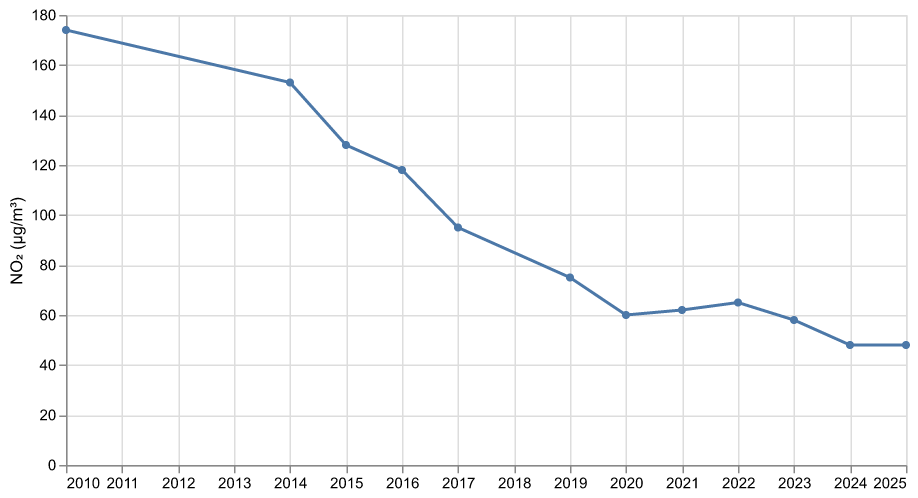

> 👀 **You should see:** the same line, now with a gap between 2010 and 2014: four years apart, as they were. The fall is slower than it looked.

> **Teacher:** **Expected:** "It squeezes four years into one step." This is the lecture's first trick (the window) done by
> accident: an honest chart shows the gap. Ask which of the five tests it fails (honest context).

## C · Say it, and mark the limit (12 min · Build-its *Say the finding in the title*, *Write on the chart*)

Now build the chart in layers, as the lecture did with `line + limit`: each layer is its own `alt.Chart`, and `+`
puts them on top of each other. The one added **last** is drawn **on top**.

**C1.** A shaded band from the limit (40) to the top of the chart: "over the limit". `mark_rect` with `y` and `y2`
draws a band between two values.

In [8]:
red = '#c8102e'
years = alt.X('year:Q', title=None, axis=alt.Axis(format='d'), scale=alt.Scale(domain=[2010, 2025]))
height = alt.Scale(domain=[0, 180])          # the axis stays the same in every chart from here

dots = alt.OverlayMarkDef(color=red)
line = alt.Chart(brixton).mark_line(point=dots, color=red, strokeWidth=3).encode(
    x=years, y=alt.Y('no2:Q', title='NO₂ (µg/m³)', scale=height))

band = alt.Chart().mark_rect(color=red, opacity=0.07).encode(
    y=alt.datum(40), y2=alt.datum(180))     # from the limit to the top
limit = alt.Chart().mark_rule(strokeDash=[6, 4]).encode(y=alt.datum(40))
limit_words = alt.Chart().mark_text(align='left', dy=-8).encode(
    x=alt.value(6), y=alt.datum(40), text=alt.value('Legal limit: 40'))   # 6 pixels in from the left

(band + limit + limit_words + line).properties(width=560, height=300)

alt.LayerChart(...)

> 🖼️ **Plan B: the chart, as a picture**
>
> 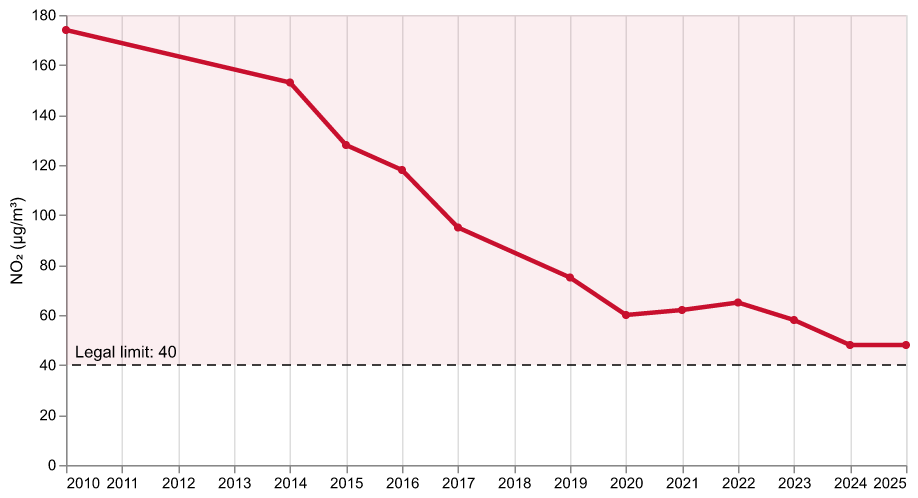

> 👀 **You should see:** a pale red band above the dashed limit line, labelled 'Legal limit: 40', and Brixton's red line falling into it but never below.

<details><summary>💡 <b>Hint</b></summary>

`mark_rect` draws a rectangle. Give it where the band starts (`y`) and where it ends (`y2`).
</details>

**C2.** The title says the finding: **both halves**, in one sentence. The subtitle says how to read the chart.

In [9]:
finding = 'Brixton Road fell 72% since 2010, but it is still London’s worst road'
how = 'NO₂ yearly average at the kerb, µg/m³. Shaded: over the legal limit of 40. 2025 is provisional.'

(band + limit + limit_words + line).properties(
    width=560, height=300, title=alt.Title(finding, subtitle=how))

alt.LayerChart(...)

> 🖼️ **Plan B: the chart, as a picture**
>
> 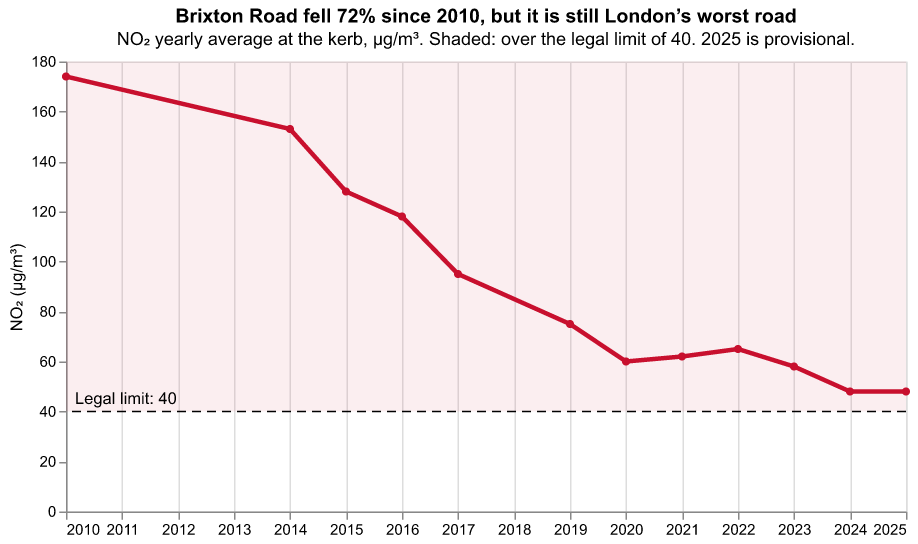

In [10]:
check('worst' in finding.lower() or 'over' in finding.lower() or 'still' in finding.lower(),
      'The title says the second half too.',
      'a title that only says it fell hides that it is still the worst.')

✅ The title says the second half too.


> **Teacher:** **Sample titles, weak to excellent:** "Brixton Road NO₂, 2010–2025" (a label); "Brixton Road's air is getting
> cleaner" (half the story: misleading); "Brixton Road fell 72% since 2010, but it is still London's worst
> road" (the finding, both halves). Read two out; the room votes with the lecture's five tests.

## D · Brixton against every road (15 min · Build-it *One line in colour, the rest grey*)

"Still the worst" needs the other roads on the chart. The lecture drew them as a second, grey layer. Here is a
neater way: **one chart of every road, with a condition on its channels**. `alt.when(test).then(a).otherwise(b)`
gives the rows that pass the test one value, and the rest another.

**D1.** Colour Brixton Road red and every other road grey, thick and thin.

In [11]:
is_brixton = alt.datum.code == 'LB4'

roads = alt.Chart(road).mark_line().encode(
    x=years,
    y=alt.Y('no2:Q', title='NO₂ (µg/m³)', scale=height),
    detail='code:N',                                            # one line per monitor
    color=alt.when(is_brixton).then(alt.value(red)).otherwise(alt.value('#b8b8b8')),
    strokeWidth=alt.when(is_brixton).then(alt.value(3)).otherwise(alt.value(1)),
)
(band + limit + roads + limit_words).properties(width=560, height=300, title=alt.Title(finding, subtitle=how))

alt.LayerChart(...)

> 🖼️ **Plan B: the chart, as a picture**
>
> 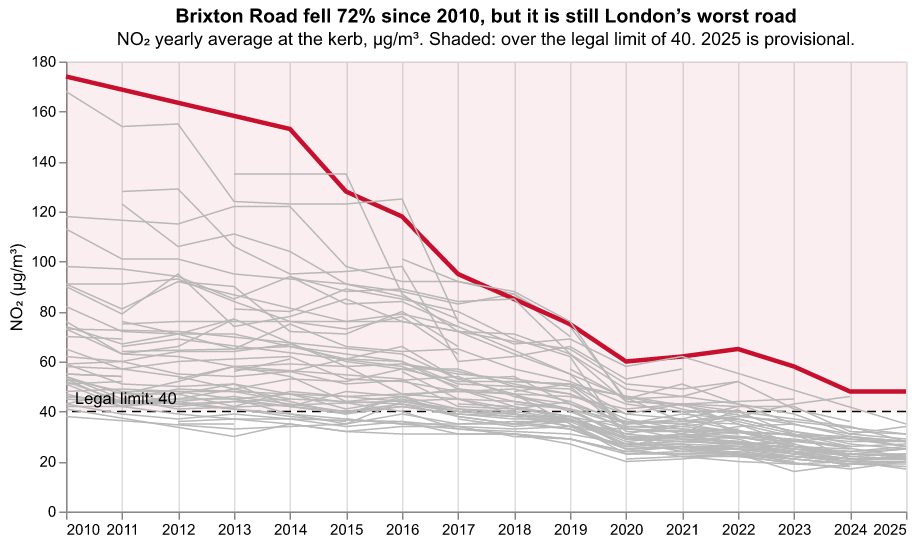

> 👀 **You should see:** about a hundred thin grey lines falling, and one thick red line above them all, the only one still in the shaded band at the end.

<details><summary>💡 <b>Hint</b></summary>

`alt.datum.code` is each row's `code`. The test is true for Brixton Road's rows only.
</details>

**D2.** No legend: label the lines where they end. Add the London median (the middle road each year) as a dashed
line, and a label at the end of Brixton's line and of the median's. `transform_aggregate` works out the median for
each year; `transform_filter` keeps only the last year for the labels.

In [12]:
median = alt.Chart(road).transform_aggregate(
    no2='median(no2)', groupby=['year']
).mark_line(color='#555555', strokeDash=[2, 3]).encode(x=years, y=alt.Y('no2:Q', scale=height))

end = 2025
brixton_label = alt.Chart(brixton).transform_filter(alt.datum.year == end).mark_text(
    align='left', dx=8, color=red, fontWeight='bold').encode(
    x=years, y=alt.Y('no2:Q', scale=height), text=alt.value('Brixton Road'))
median_label = median.transform_filter(alt.datum.year == end).mark_text(
    align='left', dx=8, color='#555555').encode(text=alt.value('London median'))

story = band + limit + roads + median + limit_words + brixton_label + median_label
story.properties(width=560, height=300, title=alt.Title(finding, subtitle=how))

alt.LayerChart(...)

> 🖼️ **Plan B: the chart, as a picture**
>
> 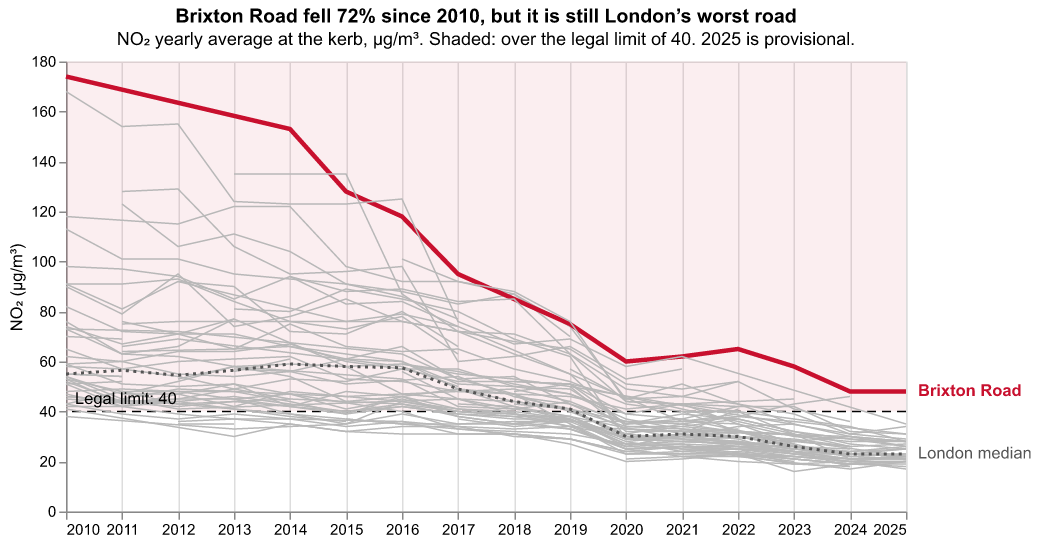

> 👀 **You should see:** the D1 chart with a dashed grey median line falling to about 23, and two labels at 2025: 'Brixton Road' in red near 48, 'London median' below.

> **Teacher:** The median falls from 55 to 23: the typical road is now well under the limit, Brixton Road still
> twice the median. That is the context the finding needs (the lecture's fourth test).

## E · Lead first, then let go (12 min · Build-it *A martini glass: chapters, then open*)

A martini glass tells the finding first, in a fixed order (the stem), then opens up for the reader (the bowl).
A **parameter** bound to buttons is the chapter; `transform_filter(chapter >= n)` shows a layer from chapter *n* on.

**E1.** Three chapters: 1. Brixton alone and the limit; 2. the notes; 3. every road and the median.

In [13]:
chapter = alt.param(value=1, bind=alt.binding_radio(options=[1, 2, 3], name='Chapter '))

notes = pd.DataFrame({
    'year': [2019, 2020, 2021, 2023],
    'at': [172, 157, 142, 127],                                   # how high each note sits
    'text': ['Central London ULEZ', 'Lockdown', 'ULEZ widened', 'London-wide'],
})
rules = alt.Chart(notes).mark_rule(color='grey').encode(x=years, y=alt.Y('at:Q', scale=height), y2=alt.datum(0))
words = alt.Chart(notes).mark_text(align='left', dx=5).encode(x=years, y=alt.Y('at:Q', scale=height), text='text:N')

# each layer brings its own data, so each is filtered on its own
stem = rules.transform_filter(chapter >= 2) + words.transform_filter(chapter >= 2)
bowl = (roads.transform_filter(chapter >= 3) + median.transform_filter(chapter >= 3)
        + median_label.transform_filter(chapter >= 3))

(band + limit + bowl + limit_words + stem + line + brixton_label).add_params(chapter).properties(
    width=560, height=300, title=alt.Title(finding, subtitle=how))

alt.LayerChart(...)

> 🖼️ **Plan B: the chart, as a picture**
>
> 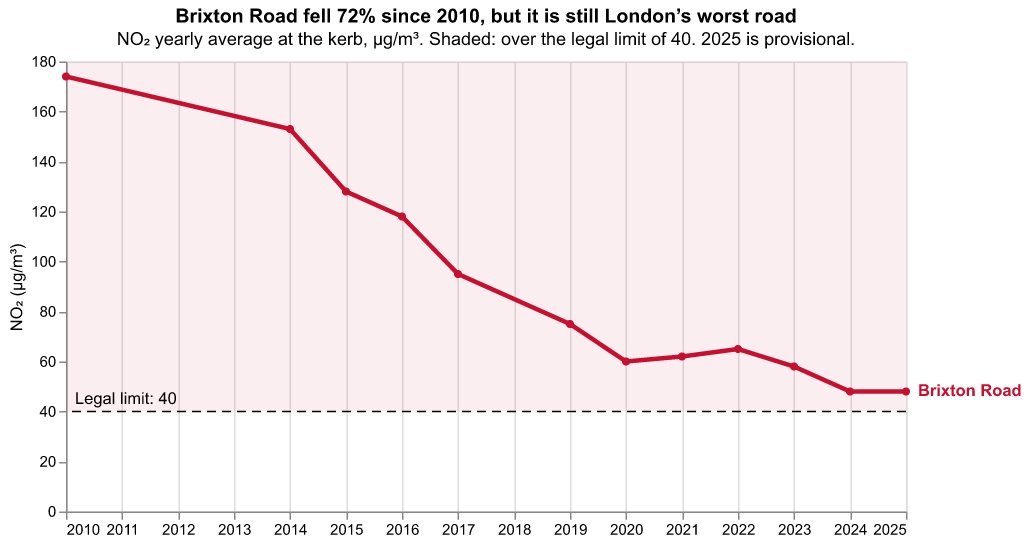

> 👀 **You should see:** buttons under the chart: Chapter 1, 2, 3. It opens on chapter 1, Brixton's red line and the limit. 2 adds the four notes; 3 adds every road in grey and the median.

<details><summary>💡 <b>Hint</b></summary>

A layer from chapter 2 on is filtered with `chapter >= 2`. A parameter only works once the chart is told about it: `.add_params(chapter)`.
</details>

> **Teacher:** The notes are London-wide events (central ULEZ April 2019, the first lockdown 2020, the ULEZ widened to the North and
> South Circular roads in October 2021, London-wide August 2023): they say when, not that each one caused Brixton's
> fall (the lecture's third trick). A pair who writes "ULEZ cleaned Brixton Road" on the chart has claimed a cause.

**Stretch (if you finish).** Let the reader isolate *any* road in chapter 3: a hover selection on `code`, and make
the hovered road dark. Start from `hover = alt.selection_point(on='pointerover', fields=['code'], empty=False)` and
add it to `roads` with `.add_params(hover)`.

## F · Hand in (3 min)

Save the notebook. On Canvas, by midday on the Friday after the lab, hand in:

1. your chart from **E**, all three chapters working;
2. one sentence: **what your chart tells, and what a reader would need to disagree with it**.

> **Teacher:** **Marking (6 marks):** one each for
> 1. the honest axis (`year:Q`, the gaps shown);
> 2. layered marks (the band, the limit and its label);
> 3. a two-part finding in the title;
> 4. a conditional channel isolating Brixton Road;
> 5. a working parameter with three chapters;
> 6. the sentence names what would change their mind (e.g. "2025 is provisional; a full year might differ"; "one
>    monitor is one spot on the road").
> 
> **Sample sentence (excellent):** "It tells that Brixton Road's NO₂ fell by 72% but is still the worst in
> London; a reader would need a full year of 2025 data, and more than one monitor on the road, to disagree."